# Факторы деградации жилого фонда в РФ: предсказание аварийности многоквартирных домов методами машинного обучения
Исследовательский вопрос: Насколько точно алгоритмы машинного обучения способны предсказывать официальный статус аварийности многоквартирного дома, и каков относительный вклад институциональных (тип управления, регион) и инфраструктурных (возраст, площадь, материал) предикторов в эту вероятность?


## Данные
Датасет взят с сайта [Если быть точным](https://tochno.st/datasets/gisgkh).

**Что в данных**: износ и аварийность жилых домов.

Данные об исправности и аварийности многоквартирных жилых домов (МКД) России, внесённых в Государственную информационную систему жилищно-коммунального хозяйства (ГИС ЖКХ). Сведения актуальны по состоянию на ноябрь 2025 года. Объём: ~956 тыс. домов, 33 признака.

### Целевая переменная
Исходный атрибут **condition** (состояние здания) распределён следующим образом:

| Состояние | Число домов | Доля |
|---|---|---|
| Исправный | 857 093 | 90,7% |
| Аварийный | 79 031 | 8,4% |
| Ветхий | 9 238 | 1,0% |

Дома без указанного состояния (`NaN`, «Не выбран») из выборки исключаются.

Моделирование проводится в два этапа:

1. **Основная задача — проблемный фонд против исправного.** Бинарная переменная **target**: «Аварийный» и «Ветхий» — класс 1 (~9%), «Исправный» — класс 0. Эта модель отвечает на исследовательский вопрос: насколько предсказуем статус проблемного дома и каков вклад институциональных и инфраструктурных факторов.
2. **Вспомогательная задача — ветхий против аварийного.** Модель обучается только на проблемном фонде (~88 тыс. домов): «Ветхий» — класс 1 (~10%), «Аварийный» — класс 0.

Разделение на два этапа обусловлено тем, что по физическим характеристикам ветхие и аварийные дома почти не различаются: медианный год ввода 1957 и 1959, медианный износ 62% и 65%; ветхие дома лишь меньше (~193 м² и 4 квартиры против ~358 м² и 8 квартир). При этом это разные правовые статусы: ветхий дом требует капитального ремонта, аварийный подлежит сносу или реконструкции и расселению. В единой трёхклассовой модели редкий (1%) и плохо отделимый класс «Ветхий» размывал бы метрики и важность признаков, тогда как двухэтапная схема позволяет интерпретировать каждое решение отдельно.

Вспомогательная модель ценна прежде всего важностью признаков. Если различие между ветхим и аварийным статусом объясняется в основном регионом и муниципалитетом, а не возрастом и материалом стен, это свидетельствует о том, что статус в значительной мере определяется административной практикой. На это указывает и концентрация ветхого фонда: 42% таких домов сосредоточены в пяти регионах (Архангельская, Самарская, Тульская, Нижегородская области, ХМАО).

### Используемые признаки
1. Инфраструктурные и архитектурные:
- **building_year** (год постройки; при пропуске — **comissioning_year**, год ввода в эксплуатацию) — базовая метрика физического старения. Значения-диапазоны вида «2001, 2002» приводятся к первому году.
- **total_area**, **residental_premises_area** (общая и жилая площадь), **flats** (число квартир) — масштаб объекта. Аварийный фонд — это преимущественно малые дома: медианная площадь ~345 м² и 7 квартир против ~1 780 м² и 27 квартир у исправных. Явно ошибочные значения площади (0, 1 м²) считаются пропусками.
- **internal_walls_type** (материал стен) и **plan_series** (серия проекта) — конструктивные характеристики. Исходные значения сильно «загрязнены» (более 2 тыс. и 57 тыс. уникальных вариантов написания), поэтому они сведены к укрупнённым группам (кирпич, панель, блоки, дерево и т.п.).
- **is_reconstructed** — бинарный признак, построенный по наличию записи в поле reconstruction_year (факт капитальных вложений в здание).

2. Институциональные и пространственные:
- **region_name** (регион) и **municipality_oktmo** (код муниципалитета по ОКТМО) — отражают бюджетную обеспеченность и пространственное неравенство.
- **house_management_type** (способ управления: УО, ТСЖ, ЖК, непосредственное управление и др.) — отражает способность собственников решать проблему коллективного действия. Доля аварийных и ветхих домов: ТСЖ — 0,8%, УО — 6%, непосредственное управление — 16%.
- **municipal_property** (наличие муниципальной собственности в доме) — индикатор участия публичного собственника: при значении «да» доля проблемного фонда достигает 45%.

### Исключённые признаки
- **Утечка целевой переменной** — признаки, которые являются следствием аварийности, а не её причиной: **deterioration** (процент износа — по нормативам статус «ветхий» определяется именно через износ), **deterioration_estimation_date**, **life_cycle_stage** (стадии «Расселён», «Снос», «Выведен из эксплуатации» наступают после признания дома аварийным), **management_organization_name/link** (у расселённых домов управляющая организация отсутствует).
- **Идентификаторы**: full_address, fias_id, cadastral_number, gisgkh_guid, postal_code.
- **Дублирующие**: region_oktmo, region_okato, municipality_okato, timezone.
- **Неинформативные**: house_type (99,9% — «Многоквартирный»), regional_property (значение «да» лишь у 55 домов), energy_efficency_class (86% пропусков).
- **Технические**: latitude, longitude — дают завышенную оценку качества из-за пространственной автокорреляции соседних домов; qc_geo — атрибут реестра, а не свойство дома.  

In [7]:
import pandas as pd
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt

In [8]:
df = pd.read_csv("data_gisgkh_157_v20260917.csv", delimiter=";", encoding="utf-8")
df.head()

,full_address,region_name,region_oktmo,region_okato,municipality_oktmo,municipality_okato,postal_code,latitude,longitude,qc_geo,...,deterioration_estimation_date,condition,internal_walls_type,reconstruction_year,energy_efficency_class,house_management_type,management_organization_name,management_organization_link,regional_property,municipal_property
0,"обл Оренбургская, г Орск, ул Докучаева, д. 23",Оренбургская область,53000000,53000000,5.372300e+10,5.342300e+10,462401.0,51.229249,58.529401,Точные координаты,...,01.01.2017,Исправный,Стены из слоистых железобетонных панелей,NaN,NaN,УО,"ООО ""УК ""ДЕЙСТВИЕ""",https://dom.gosuslugi.ru/#!/organizationView/8...,NaN,NaN
1,"Респ Башкортостан, г Нефтекамск, ул Карцева, д...",Республика Башкортостан,80000000,80000000,8.072700e+10,8.042700e+10,452687.0,56.077100,54.225304,Точные координаты,...,26.03.2025,Исправный,Стены кирпичные,NaN,NaN,УО,"ООО ""Мегаполис""",https://dom.gosuslugi.ru/#!/organizationView/3...,False,False
2,"Респ Башкортостан, г Нефтекамск, ул Карцева, д...",Республика Башкортостан,80000000,80000000,8.072700e+10,8.042700e+10,452687.0,56.077386,54.224518,Точные координаты,...,26.03.2025,Исправный,Стены кирпичные,NaN,NaN,УО,"ООО ""Мегаполис""",https://dom.gosuslugi.ru/#!/organizationView/3...,False,False
3,"Респ Башкортостан, г Нефтекамск, ул Карцева, д...",Республика Башкортостан,80000000,80000000,8.072700e+10,8.042700e+10,452687.0,56.077664,54.223853,Точные координаты,...,03.04.2025,Исправный,Стены кирпичные,NaN,С (Нормальный),УО,"ООО ""УК ""СВОЙ ДОМ""",https://dom.gosuslugi.ru/#!/organizationView/9...,False,False
4,"Респ Башкортостан, г Нефтекамск, ул Карцева, д...",Республика Башкортостан,80000000,80000000,8.072700e+10,8.042700e+10,452687.0,56.077926,54.223225,Точные координаты,...,26.03.2025,Исправный,Стены кирпичные,NaN,С (Нормальный),УО,"ООО ""УК ""СВОЙ ДОМ""",https://dom.gosuslugi.ru/#!/organizationView/9...,False,False


In [9]:
TARGET = "condition"
RANDOM_STATE = 42

COLORS = {
    "accent": "#4654f5",
    "header": "#959ef2",
    "background": "#EEEEEE",
    "text": "#000000",
    "index_background": "#A0CCFF"
}

PLOT_COLOR = COLORS["accent"]

def style_table(df, caption, colors=COLORS, hide_index=True):
    styler = df.style.set_caption(caption)
    if hide_index:
        styler = styler.hide(axis="index")
    return styler.set_table_styles([
        {"selector": "caption", "props": f"font-size:16px; font-weight:bold; color:{colors['text']};"},
        {"selector": "th", "props": f"background-color:{colors['header']}; color:{colors['text']}; border:1px solid #ccc;"},
        {"selector": "td", "props": f"background-color:{colors['background']}; color:{colors['text']}; border:1px solid #ccc;"},
        {"selector": ".row_heading", "props": f"background-color:{colors['index_background']}; color:{colors['text']}; font-weight:bold; border:1px solid #ccc;"},
    ])

In [10]:
info_df = pd.DataFrame(
    {
        'Column': df.columns,
        'Non-Null': df.notnull().sum().values,
        'Dtype': df.dtypes.values,
    }
)
style_table(info_df, "Dataframe info")

Column,Non-Null,Dtype
full_address,956147,str
region_name,956147,str
region_oktmo,956147,int64
region_okato,956147,int64
municipality_oktmo,938351,float64
municipality_okato,938351,float64
postal_code,955464,float64
latitude,937904,float64
longitude,937904,float64
qc_geo,938351,str


In [11]:
# Data overview

overview = pd.DataFrame({
    "Metric": ["Shape", "Number of features", "Missing Values", "Duplicate Rows"],
    "Value": [df.shape, df.drop(TARGET, axis=1).columns.size, df.isnull().sum().sum(), df.duplicated().sum()]
})
style_table(overview, "Dataset Overview")

Metric,Value
Shape,"(956147, 33)"
Number of features,32
Missing Values,4725859
Duplicate Rows,0


In [12]:
# Target distribution

target_distribution = df[TARGET].value_counts()
target_distribution
target_distribution_df = pd.DataFrame({
    "Condition": target_distribution.index,
    "Count": target_distribution.values,
    "Percentage": (target_distribution.values / target_distribution.sum()) * 100  
})
style_table(target_distribution_df, "Target distribution").format({
    "Count": "{:,.0f}",
    "Percentage": "{:.2f}%"
})

Condition,Count,Percentage
Исправный,"857,093",90.66%
Аварийный,"79,031",8.36%
Ветхий,"9,238",0.98%
Не выбран,29,0.00%


In [13]:
# Missing values

missing_values = df.isna().sum()
missing_values_df = pd.DataFrame({
    "Feature": missing_values.index,
    "Count": missing_values.values,
    "Percentage": (missing_values.values / len(df)) * 100
})

style_table(missing_values_df, "Missing values").format({
    "Count": "{:,.0f}",
    "Percentage": "{:.2f}%"
})

Feature,Count,Percentage
full_address,0,0.00%
region_name,0,0.00%
region_oktmo,0,0.00%
region_okato,0,0.00%
municipality_oktmo,"17,796",1.86%
municipality_okato,"17,796",1.86%
postal_code,683,0.07%
latitude,"18,243",1.91%
longitude,"18,243",1.91%
qc_geo,"17,796",1.86%


In [94]:
style_table(df.describe().T, "Numeric describe", hide_index=False).format("{:,.2f}")

,count,mean,std,min,25%,50%,75%,max
region_oktmo,"816,990.00","46,658,925.08","26,608,237.05","1,000,000.00","24,000,000.00","46,000,000.00","68,000,000.00","99,000,000.00"
region_okato,"816,990.00","46,626,732.08","26,608,428.50","1,000,000.00","24,000,000.00","46,000,000.00","68,000,000.00","99,000,000.00"
municipality_okato,"805,287.00","47,033,809,572.15","26,557,890,816.83","1,201,802,001.00","25,203,501,000.00","46,415,000,483.00","68,401,368,000.00","99,401,000,000.00"
postal_code,"816,592.00","400,161.63","197,929.94",0.00,"186,985.00","400,051.00","620,092.00","694,923.00"
latitude,"804,926.00",54.95,4.98,41.62,52.78,55.55,57.45,73.51
longitude,"804,926.00",55.03,28.46,-179.48,37.73,43.95,60.59,179.26
flats,"805,285.00",56.53,85.12,0.00,8.00,27.00,75.00,"5,545.00"
comissioning_year,"816,990.00","1,975.62",24.76,"1,801.00","1,962.00","1,975.00","1,989.00","2,026.00"
building_year,"816,990.00","1,975.78",24.34,"1,801.00","1,962.00","1,975.00","1,989.00","2,026.00"
total_area,"816,990.00","3,545.93","6,456.86",1.90,527.00,"1,776.40","4,168.58","826,976.00"


In [15]:
style_table(df.describe(include='str').T, "String describe", hide_index=False)

,count,unique,top,freq
full_address,956147,956006,"край Алтайский, р-н Краснощёковский, с Краснощёково, ул Ленина, д. 144",2
region_name,956147,85,Московская область,52104
qc_geo,938351,6,Точные координаты,726044
timezone,938351,11,UTC+3,550028
fias_id,956147,956021,fca0a054-4f63-4dbf-b985-c87c47c5b4f9,2
cadastral_number,934804,933401,отсутствует,16
gisgkh_guid,956147,956147,762cf039-7a6f-4219-ba47-a7d895462e84,1
house_type,956147,2,Многоквартирный,955472
life_cycle_stage,923199,7,Эксплуатация,904811
building_year,890127,1175,1960,21957


## Разведочный анализ данных (EDA)
*Проблема пропусков*: В исходных данных зафиксировано значительное число пропусков в категориальных переменных (например, plan_series, municipality_name). В логике нашего исследования отсутствие записи в государственном реестре само по себе является информативным сигналом (дефицит административного контроля). Поэтому пропуски в категориальных номинальных шкалах заполнены значением «Не указано». Пропуски в непрерывных числовых переменных (площадь) заполнены медианными значениями.

### Очистка данных

In [16]:
# Очистка целевой переменной

df = df[df["condition"] != "Не выбран"]

In [17]:
# Преобразование comissioning_year

df["comissioning_year"] = df["comissioning_year"].astype("Int64")

mask = (df['comissioning_year'] > 1800) & (df['comissioning_year'] <= 2026)
df = df[mask]

style_table(pd.DataFrame({"Count": [len(mask) - mask.sum()], "Percentage": [1 - mask.sum() / len(mask)]}), "Deleted comissioning_year rows").format({
    "Count": "{:,.0f}",
    "Percentage": "{:.2f}%"
})

Count,Percentage
"22,848",0.02%


In [18]:
# Преобразование building_year

df["building_year"] = df["building_year"].fillna(df["comissioning_year"])
df["building_year"] = df["building_year"].str.split(",").str[0].astype("Int64")

mask = (df['building_year'] > 1800) & (df['building_year'] <= 2026)
df = df[mask]

style_table(pd.DataFrame({"Count": [len(mask) - mask.sum()], "Percentage": [1 - mask.sum() / len(mask)]}), "Deleted building_year rows").format({
    "Count": "{:,.0f}",
    "Percentage": "{:.2f}%"
})

Count,Percentage
"51,467",0.06%


In [19]:
# Преобразование признаков площади

mask = (df["total_area"] > 1) & (df["residental_premises_area"] > 1)

df = df[mask]
df["residental_ratio"] = df["residental_premises_area"] / df["total_area"]
df["flats_area_ratio"] = df["flats"] / df["total_area"]

style_table(pd.DataFrame({"Count": [len(mask) - mask.sum()], 
                          "Percentage": [1 - mask.sum() / len(mask)]}), 
                          "Deleted area rows").format({
                              "Count": "{:,.0f}",
                              "Percentage": "{:.2f}%"
                          })

Count,Percentage
"64,813",0.07%


In [20]:
# Топ 95% категорий признака internal_walls_type

vc = df["internal_walls_type"].str.lower().str.strip().value_counts()
cum = vc.cumsum() / vc.sum()
d = {q: (cum < q).sum() + 1 for q in (.8, .9, .95, .99)}

top = d.get(0.95)
materials = vc.head(top)
materials_df = pd.DataFrame({"Material": materials.index, 
                             "Count": materials.values,
                             "Percentage": materials.values / len(df["internal_walls_type"]) * 100
})
style_table(materials_df,"Top 95% walls type rows").format({
    "Count": "{:,.0f}",
    "Percentage": "{:.2f}%"
})

Material,Count,Percentage
стены кирпичные,"333,092",40.77%
стены из слоистых железобетонных панелей,"49,044",6.00%
стены из несущих панелей,"40,730",4.99%
стены деревянные,"35,281",4.32%
стены рубленные из бревен и брусчатые,"27,059",3.31%
стены из ж/б панелей,"25,254",3.09%
стены из крупноразмерных блоков и однослойных несущих панелей,"21,460",2.63%
"стены деревянные, сборно-щитовые","17,091",2.09%
стены из шлакоблоков,"16,512",2.02%
панельные,"15,858",1.94%


In [21]:
import re

WALL_RULES = [
    ("Дерево",    r"дерев|брус|бревен|бревн|рублен|сруб|щит|каркасн|засыпн|арболит|арбоблок|фибролит"),
    ("Монолит",   r"монолит"),
    ("Кирпич",    r"кирпич"),
    ("Шлакоблок", r"шлак"),
    ("Блоки",     r"блок|газобет|пенобет|газосилик|ячеист|силикальцит|камн|поротерм"),
    ("Панель",    r"панел|плит|железобет|ж/б"),
    ("Гипсолит",  r"гипс"),
]

def map_wall_part(part):
    for group, pattern in WALL_RULES:
        if re.search(pattern, part):
            return group
    return None

def map_walls(value):
    if pd.isna(value) or not str(value).strip():
        return "Не указано"
    text = str(value).lower().replace("\u00ad", "")
    parts = [p.strip() for p in re.split(r"[,;/+]", text) if p.strip()]
    groups = {g for g in map(map_wall_part, parts) if g}
    if not groups:
        return "Прочее"
    return groups.pop() if len(groups) == 1 else "Смешанные"

uniq = df["internal_walls_type"].dropna().unique()
walls_mapping = {v: map_walls(v) for v in uniq}
df["walls_group"] = df["internal_walls_type"].map(walls_mapping).fillna("Не указано")

In [22]:
walls_group = df["walls_group"].value_counts(dropna=False)

walls_group_df = pd.DataFrame({
    "Walls type": walls_group.index,
    "Count": walls_group.values,
    "Percentage": (walls_group.values / len(df["walls_group"])) * 100
})

style_table(walls_group_df, "Walls type").format({
    "Count": "{:,.0f}",
    "Percentage": "{:.2f}%"
})

Walls type,Count,Percentage
Кирпич,"334,478",40.94%
Панель,"167,563",20.51%
Дерево,"116,409",14.25%
Не указано,"75,184",9.20%
Блоки,"49,654",6.08%
Смешанные,"27,181",3.33%
Шлакоблок,"18,129",2.22%
Монолит,"16,637",2.04%
Гипсолит,"11,640",1.42%
Прочее,115,0.01%


In [23]:
# Топ 95% категорий признака plan_series

vc = df["plan_series"].str.lower().str.strip().value_counts()
cum = vc.cumsum() / vc.sum()
d = {q: (cum < q).sum() + 1 for q in (.8, .9, .95, .99)}

print(f"Топ 95% категорий признака plan_series {d.get(0.95)}")

Топ 95% категорий признака plan_series 17234


In [24]:
PLAN_KIND_RULES = [
    ("Индивидуальный", r"не ?типов|нетипов|не ?серийн|инд|автор|^ип$"),
    ("Серийный",       r"(?<!\d)(?:[iп1]\s*-?\s*)?\d{2,3}(?!\d)"),
    ("Типовой",        r"типов|повторн|экспер"),
]

def map_plan_kind(raw):
    if pd.isna(raw):
        return "Не указано"
    parts = [p.strip() for p in re.split(r"[,;:/]", str(raw).lower()) if p.strip()]
    kinds = set()
    for part in parts:
        for group, rule in PLAN_KIND_RULES:
            if re.search(rule, part):
                kinds.add(group)
                break
    for group in ("Серийный", "Индивидуальный", "Типовой"):   # приоритет при конфликте
        if group in kinds:
            return group
    return "Не указано"

uniq = df["plan_series"].dropna().unique()
plan_kind_mapping = {v: map_plan_kind(v) for v in uniq}
df["plan_kind"] = df["plan_series"].map(plan_kind_mapping).fillna("Не указано")

In [25]:
plan_kind = df["plan_kind"].value_counts(dropna=False)

plan_kind_df = pd.DataFrame({
    "Plan kind": plan_kind.index,
    "Count": plan_kind.values,
    "Percentage": (plan_kind.values / len(df["plan_kind"])) * 100
})

style_table(plan_kind_df, "Plan kind").format({
    "Count": "{:,.0f}",
    "Percentage": "{:.2f}%"
})

Plan kind,Count,Percentage
Не указано,"526,811",64.48%
Серийный,"172,098",21.06%
Индивидуальный,"87,033",10.65%
Типовой,"31,048",3.80%


In [26]:
# Преобразование municipality_oktmo в строковое значение

df["municipality_oktmo"] = df["municipality_oktmo"].astype("Int64").astype(str).fillna("Не указано")

In [188]:
# Преобразование flats в целочисленное значение

df["flats"] = df["flats"].astype("Int64")

In [27]:
house_type = df["house_type"].value_counts(dropna=False) 

house_type_df = pd.DataFrame({
    "Type": house_type.index,
    "Count": house_type.values,
    "Percentage": house_type.values / len(df["house_type"]) * 100
})

style_table(house_type_df, "House type type").format({
    "Count": "{:,.0f}",
    "Percentage": "{:.2f}%"
})

Type,Count,Percentage
Многоквартирный,"816,797",99.98%
Жилой,193,0.02%


Признак house_type можно исключить как неинформативный

In [28]:
regional_property = df["regional_property"].value_counts(dropna=False)

regional_property_df = pd.DataFrame({
    "Type": regional_property.index,
    "Count": regional_property.values,
    "Percentage": regional_property.values / len(df["regional_property"]) * 100
})

style_table(regional_property_df, "Regional property").format({
    "Count": "{:,.0f}",
    "Percentage": "{:.2f}%"
})

Type,Count,Percentage
nan,"450,639",55.16%
False,"366,303",44.84%
True,48,0.01%


Признак regional_property можно исключить как неинформативный (только 0.01% домов в датасете являются региональной собственностью)

In [29]:
energy_efficency_class = df["energy_efficency_class"].value_counts(dropna=False)

energy_efficency_class_df = pd.DataFrame({
    "Type": energy_efficency_class.index,
    "Count": energy_efficency_class.values,
    "Percentage": energy_efficency_class.values / len(df["energy_efficency_class"]) * 100
})

style_table(energy_efficency_class_df, "Energy efficency class").format({
    "Count": "{:,.0f}",
    "Percentage": "{:.2f}%"
})

Type,Count,Percentage
nan,"693,412",84.87%
Нет,"43,803",5.36%
С (Нормальный),"21,992",2.69%
D (Пониженный),"14,151",1.73%
E (Низкий),"12,600",1.54%
В (Высокий),"6,042",0.74%
Е (Пониженный - приказ Минстроя №399/пр),"4,954",0.61%
В+ (Высокий),"4,610",0.56%
D (Нормальный - приказ Минстроя №399/пр),"4,407",0.54%
А (Очень высокий),"2,584",0.32%


Признак energy_efficency_class можно исключить как неинформативный (84.87% строк не заполнены)

In [31]:
# Виды управления многоквартирными домами

managment_type = df["house_management_type"].value_counts()
managment_type_df = pd.DataFrame({
    "Type": managment_type.index,
    "Count": managment_type.values,
    "Percentage": managment_type.values / len(df["house_management_type"]) * 100
})

style_table(managment_type_df, "House managment type").format({
    "Count": "{:,.0f}",
    "Percentage": "{:.2f}%"
})

Type,Count,Percentage
УО,"589,850",72.20%
Непосредственное управление,"167,097",20.45%
ТСЖ,"35,508",4.35%
Не выбран,"12,672",1.55%
ЖК,"7,635",0.93%
"Выбран, но не реализован",488,0.06%
Иной кооператив,236,0.03%


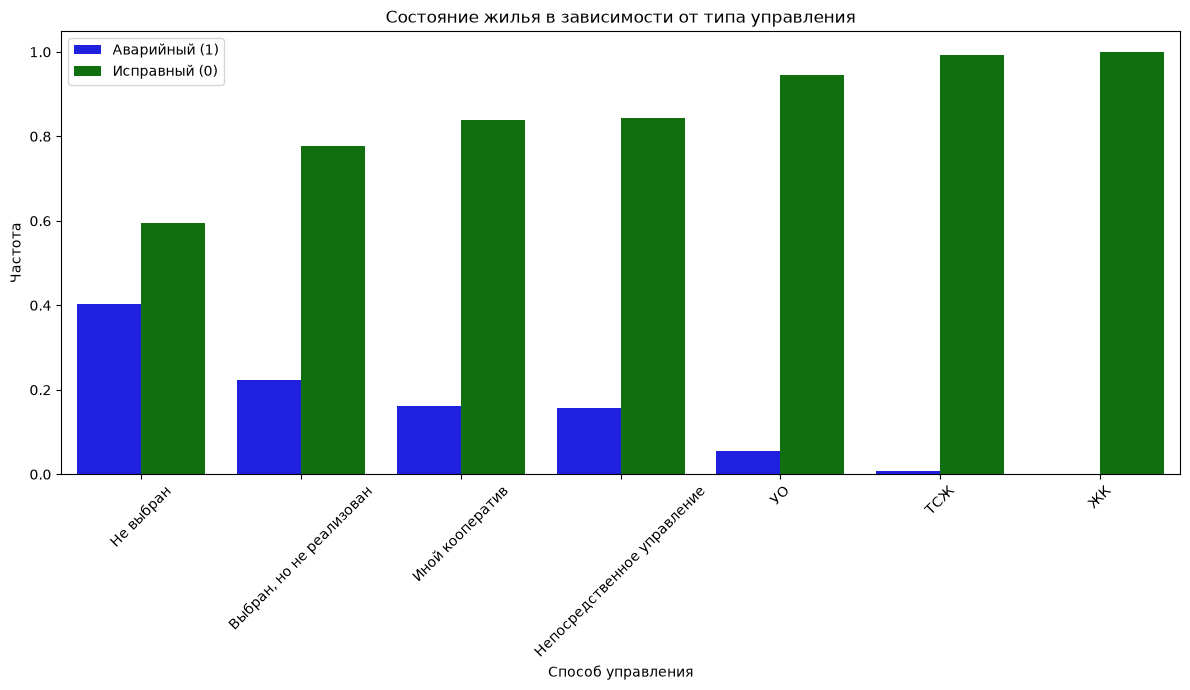

In [625]:
# Состояние жилья в зависимости от типа управления

temp = df.groupby(["house_management_type", "condition"])["condition"].count().rename("count").reset_index()
temp["freq"] = temp["count"] / temp.groupby("house_management_type")["count"].transform("sum")

# order = (temp[temp["condition"] == 1].sort_values("freq", ascending=False)["house_management_type"])
# print(order)

# temp
order = temp[temp["condition"] == 1].sort_values("freq", ascending=False)["house_management_type"]

fig, ax = plt.subplots(figsize=(12,7))
sns.barplot(temp, x="house_management_type", y="freq", hue="condition", ax=ax, hue_order=[1,0], order=order, palette={0:"g", 1:"b"}, legend=True)
handle, _ = ax.get_legend_handles_labels()
plt.title("Состояние жилья в зависимости от типа управления")
plt.legend(handles=handle, labels=["Аварийный (1)", "Исправный (0)"])
plt.xticks(rotation=45)
plt.xlabel("Способ управления")
plt.ylabel("Частота")
plt.tight_layout()
plt.show()

In [33]:
# Признак is_reconstrucsted

df['is_reconstructed'] = df['reconstruction_year'].notna().astype(int)

In [222]:
is_reconstructed = df["is_reconstructed"].value_counts(dropna=False)

is_reconstructed_df = pd.DataFrame({
    "Type": is_reconstructed.index.astype("bool"),
    "Count": is_reconstructed.values,
    "Percentage": is_reconstructed.values / len(df["is_reconstructed"]) * 100
})

style_table(is_reconstructed_df, "Is reconstructed").format({
    "Count": "{:,.0f}",
    "Percentage": "{:.2f}%"
})

Type,Count,Percentage
False,"714,430",87.45%
True,"102,560",12.55%


In [223]:
municipal_property = df["municipal_property"].value_counts(dropna=False)

municipal_property_df = pd.DataFrame({
    "Type": municipal_property.index,
    "Count": municipal_property.values,
    "Percentage": municipal_property.values / len(df["municipal_property"]) * 100
})

style_table(municipal_property_df, "Municipal property").format({
    "Count": "{:,.0f}",
    "Percentage": "{:.2f}%"
})

Type,Count,Percentage
False,"444,445",54.40%
nan,"370,797",45.39%
True,"1,748",0.21%


### Распределение признаков

In [257]:
TARGET = "condition"

df[TARGET] = df[TARGET].map(lambda x: 1 if x in ['Аварийный', 'Ветхий'] else 0)

In [332]:
category_features = [
    "walls_group", 
    "plan_kind", 
    "region_name", 
    "municipality_oktmo", 
    "house_management_type",
]

continues_features = [
    "building_year", 
    "comissioning_year", 
    "total_area", 
    "residental_premises_area", 
    "flats"
]

ratio_features = [
    "flats_area_ratio",
    "residental_ratio"
]

boolean_features = [
    "is_reconstructed",
    "municipal_property"
]


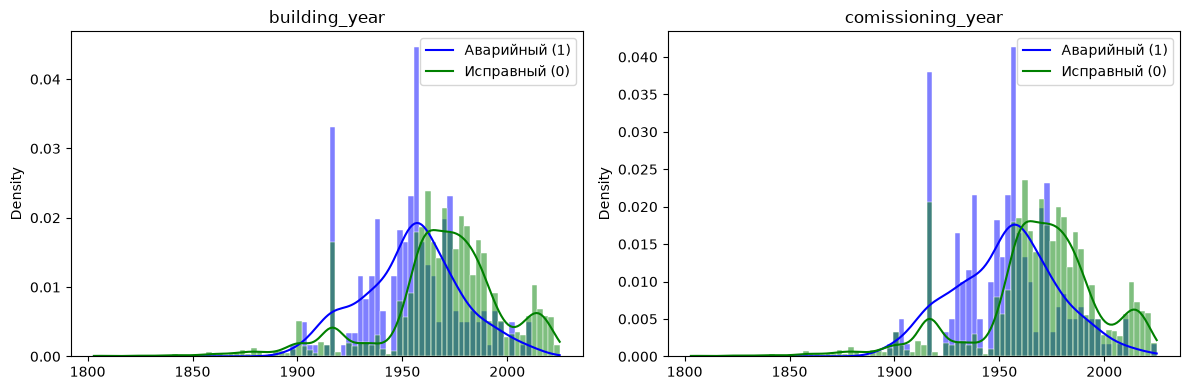

In [481]:
# Распределение по году постройки и ввода в эксплуатацию

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, col in zip(axes.flat, ["building_year", "comissioning_year"]):
    sns.histplot(
        data=df.dropna(),
        x=col,
        hue=TARGET,
        edgecolor = "white",
        color = PLOT_COLOR,
        stat="density",
        kde=True,
        common_norm=False,
        palette={0:"g", 1:"b"},
        ax=ax
    )
    ax.set_title(col, color=COLORS["text"])
    ax.legend(["Аварийный (1)", "Исправный (0)"])
    ax.set_xlabel("")
    ax.set_ylabel("Density")

plt.tight_layout()
plt.show()

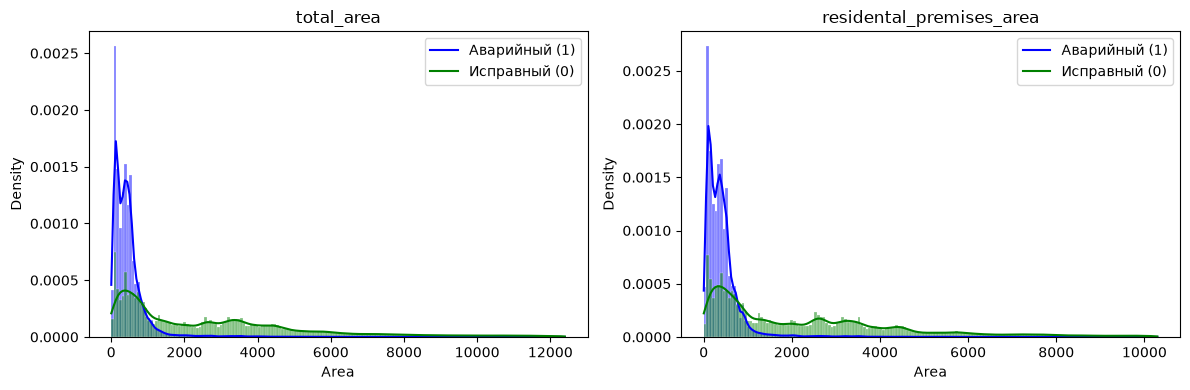

In [482]:
# Распределение по площадям: общая и жилых помещений

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, col in zip(axes.flat, ["total_area", "residental_premises_area"]):
    q = df[col].quantile(0.95)
    mask = df[col] <= q
    sns.histplot(
        data=df[mask],
        x=col,
        hue=TARGET,
        edgecolor = "white",
        color = PLOT_COLOR,
        stat="density",
        common_norm=False,
        kde=True,
        palette={0:"g", 1:"b"},
        ax=ax
    )
    ax.set_title(col, color=COLORS["text"])
    ax.legend(["Аварийный (1)", "Исправный (0)"])
    ax.set_xlabel("Area")
    ax.set_ylabel("Density")

plt.tight_layout()
plt.show()

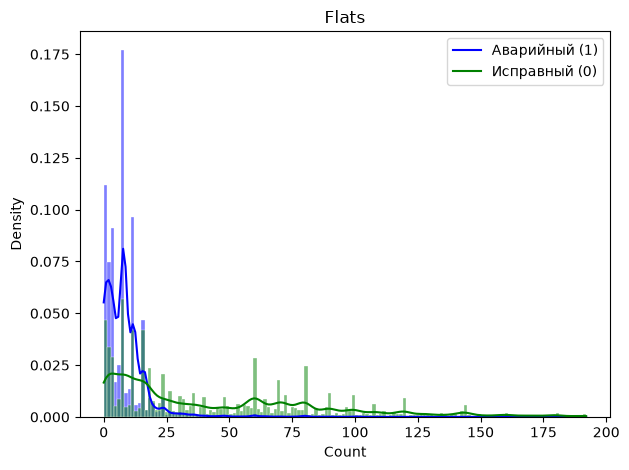

In [483]:
# Распределение количества квартир в домах

q = df["flats"].quantile(0.95)
mask = df["flats"] <= q
sns.histplot(
    data=df[mask],
    x="flats",
    hue=TARGET,
    edgecolor = "white",
    color = PLOT_COLOR,
    stat="density",
    kde=True,
    common_norm=False,
    palette={0:"g", 1:"b"},
)
plt.legend(["Аварийный (1)", "Исправный (0)"])
plt.title("Flats", color=COLORS["text"])
plt.xlabel("Count")
plt.ylabel("Density")
plt.tight_layout()
plt.show()

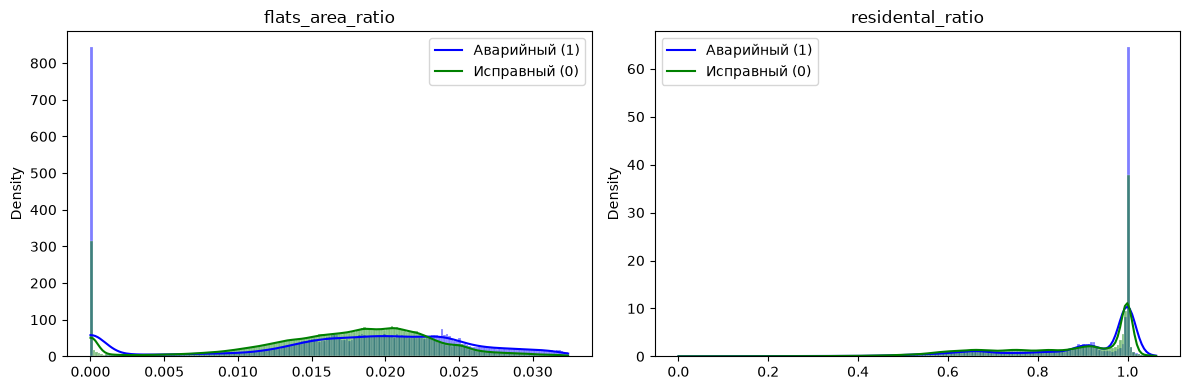

In [484]:
# Распределение по году постройки и ввода в эксплуатацию

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, col in zip(axes.flat, ["flats_area_ratio", "residental_ratio"]):
    q = df[col].quantile(0.95)
    mask = df[col] <= q
    sns.histplot(
        data=df[mask],
        x=col,
        hue=TARGET,
        edgecolor = "white",
        color = PLOT_COLOR,
        stat="density",
        kde=True,
        common_norm=False,
        palette={0:"g", 1:"b"},
        ax=ax
    )
    ax.legend(["Аварийный (1)", "Исправный (0)"])
    ax.set_title(col, color=COLORS["text"])
    ax.set_xlabel("")
    ax.set_ylabel("Density")

plt.tight_layout()
plt.show()

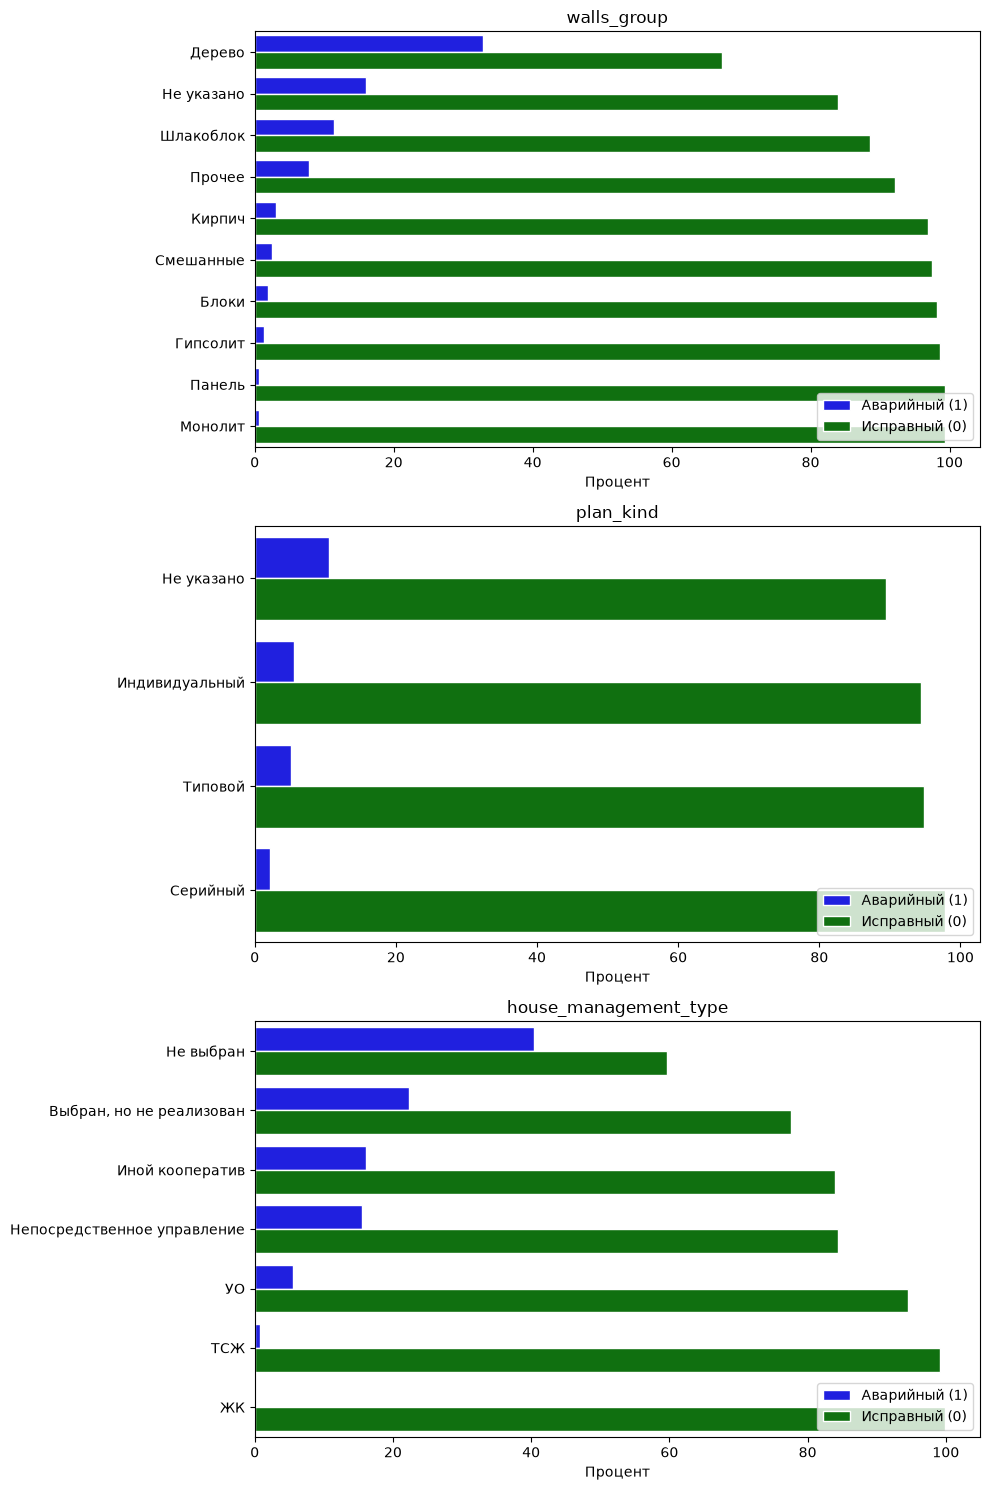

In [665]:
# Распределение категориальных переменных
# ["walls_group", "plan_kind", "house_management_type"]

fig, axes = plt.subplots(3, 1, figsize=(10,15))
for ax, col in zip(axes.flat, ["walls_group", "plan_kind", "house_management_type"]):
    temp = df.groupby([col, TARGET])[TARGET].count().reset_index(name="count")
    temp["percentage"] = temp["count"] / temp.groupby(col)["count"].transform("sum") * 100

    order = (
        temp[temp[TARGET] == 1]
        .sort_values("percentage", ascending=False)[col]
        .tolist()
    )

    sns.barplot(
        data=temp,
        y=col,
        x="percentage",
        hue=TARGET,
        edgecolor="white",
        palette={0: "g", 1: "b"},
        hue_order=[1, 0],
        ax=ax,
        order=order,
        legend=True
    )
    
    handles, _ = ax.get_legend_handles_labels()

    ax.legend(
        handles=handles, 
        labels=["Аварийный (1)", "Исправный (0)"],
        loc="lower right"
    )
    ax.set_title(col, color=COLORS["text"])
    ax.set_ylabel("")
    ax.set_xlabel("Процент")

plt.tight_layout()
plt.show()

# temp = df.groupby([col, TARGET])[TARGET].count().reset_index(name="count")
# temp["percentage"] = temp["count"] / temp.groupby(col)["count"].transform("sum") * 100
# # temp["percantage"] = temp["sum"] / temp["count"] * 100
# temp

### Распределение целевой переменной по признакам

Text(0, 0.5, 'Количество домов')

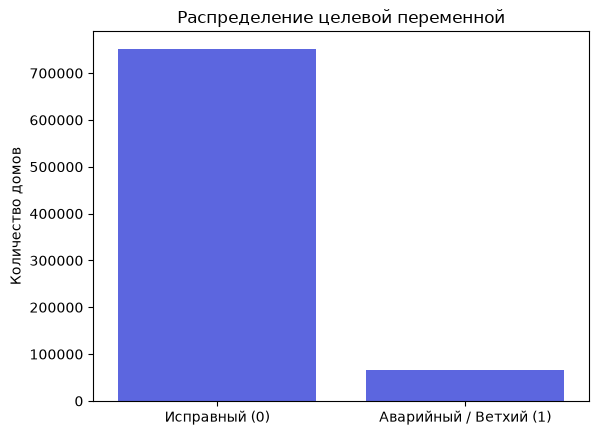

In [432]:
# Распределение целевой переменой

sns.countplot(
    data=df,
    x=TARGET,
    color=PLOT_COLOR
)
plt.title("Распределение целевой переменной")
plt.xticks(ticks=[0,1], labels=["Исправный (0)", "Аварийный / Ветхий (1)"])
plt.xlabel("")
plt.ylabel("Количество домов")

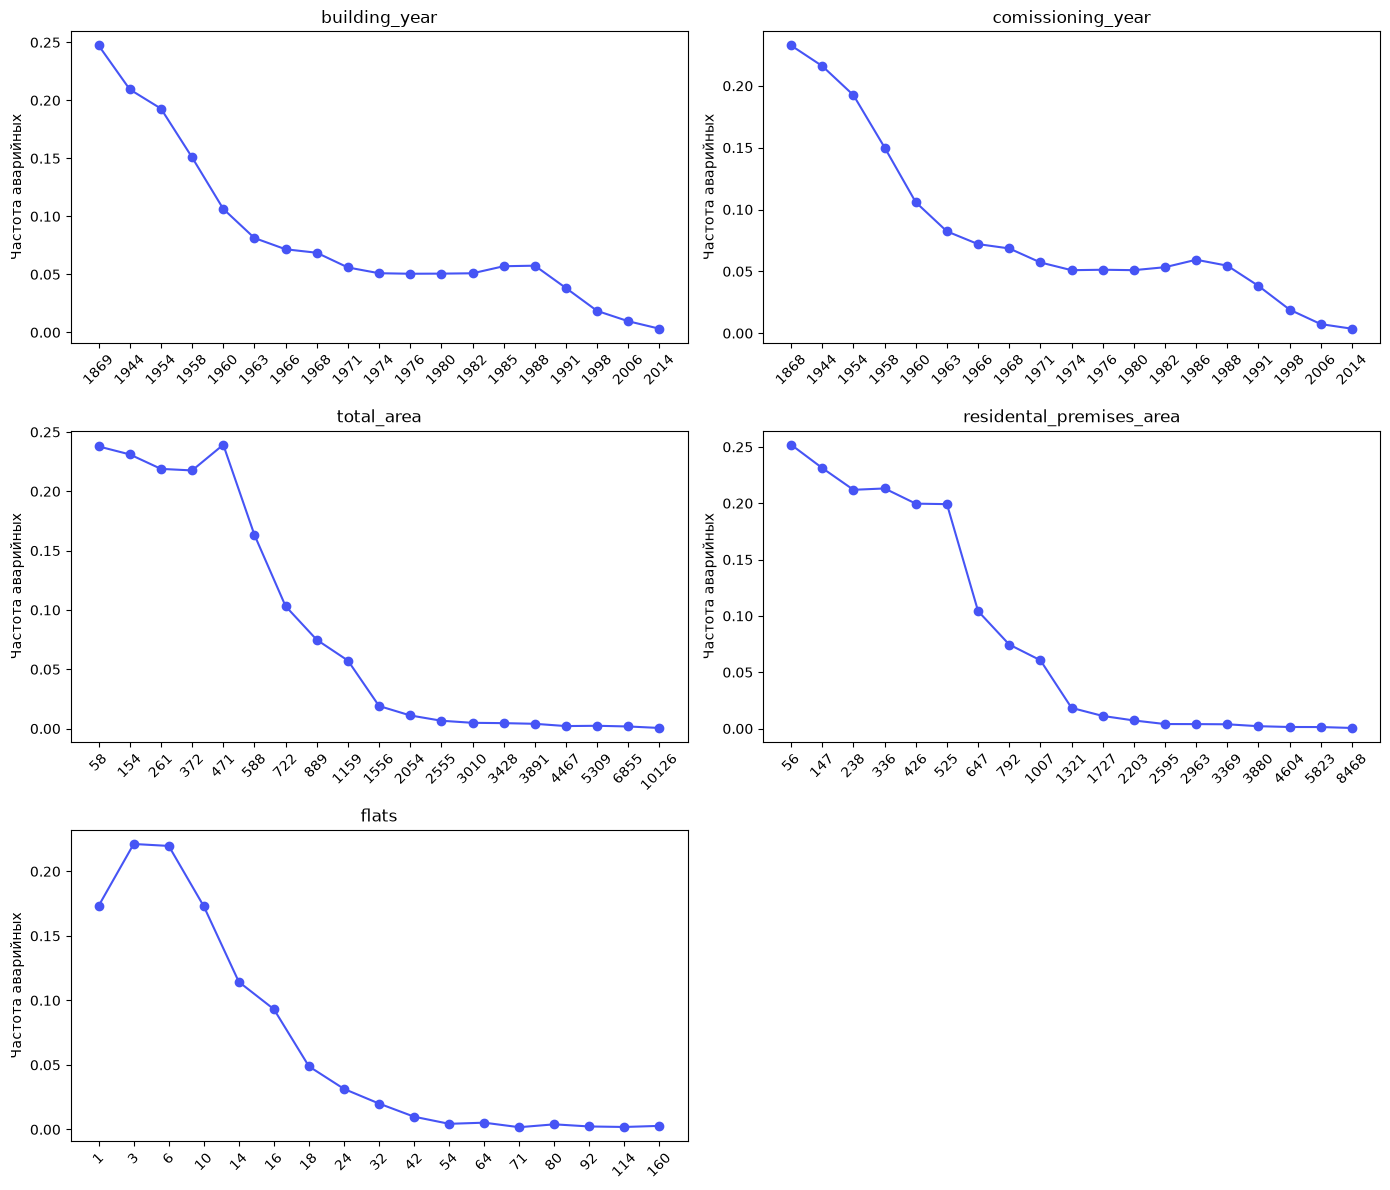

In [427]:
quantiles = np.linspace(0, 1, 20, endpoint=False)

fig, axes = plt.subplots(3, 2, figsize=(14,12))
for ax, col in zip(axes.flat, continues_features):
    bins = pd.qcut(df[col], q=quantiles, duplicates="drop")
    temp = df.groupby(bins)[TARGET].mean()
    ax.plot(
        temp.values,
        marker='o',
        color=PLOT_COLOR
    )
    # ax.set_ylim(0,1)
    ax.set_xticks(ticks=range(len(temp)), labels=[f"{b.mid:.0f}" for b in temp.index], rotation=45)
    ax.set_title(col, color=COLORS["text"])
    ax.set_ylabel("Частота аварийных")

for ax in axes.flat[len(continues_features):]:
    ax.remove()

plt.tight_layout()
plt.show()

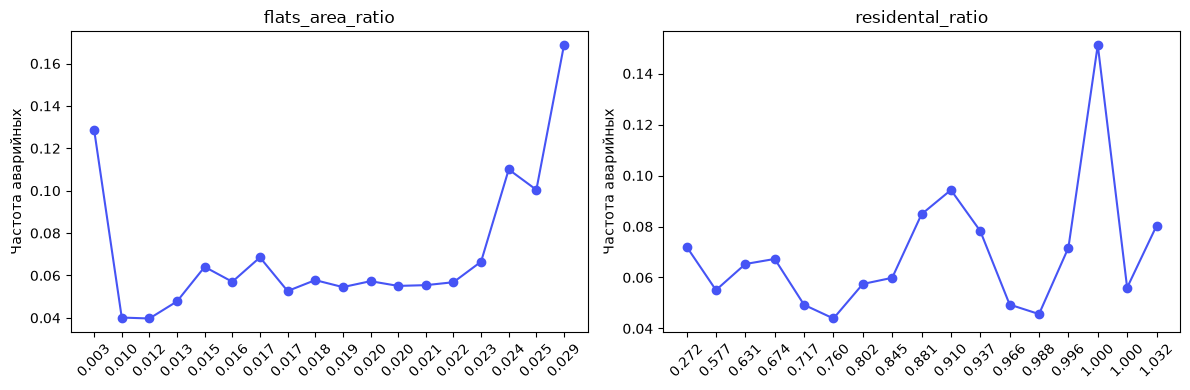

In [428]:
quantiles = np.linspace(0, 1, 20, endpoint=False)

fig, axes = plt.subplots(1, 2, figsize=(12,4))
for ax, col in zip(axes.flat, ratio_features):
    bins = pd.qcut(df[col], q=quantiles, duplicates="drop")
    temp = df.groupby(bins)[TARGET].mean()
    ax.plot(
        temp.values,
        marker='o',
        color=PLOT_COLOR
    )
    # ax.set_ylim(0,1)
    ax.set_xticks(ticks=range(len(temp)), labels=[f"{b.mid:.3f}" for b in temp.index], rotation=45)
    ax.set_title(col, color=COLORS["text"])
    ax.set_ylabel("Частота аварийных")

plt.tight_layout()
plt.show()

In [389]:
df.municipality_oktmo.nunique()

16656

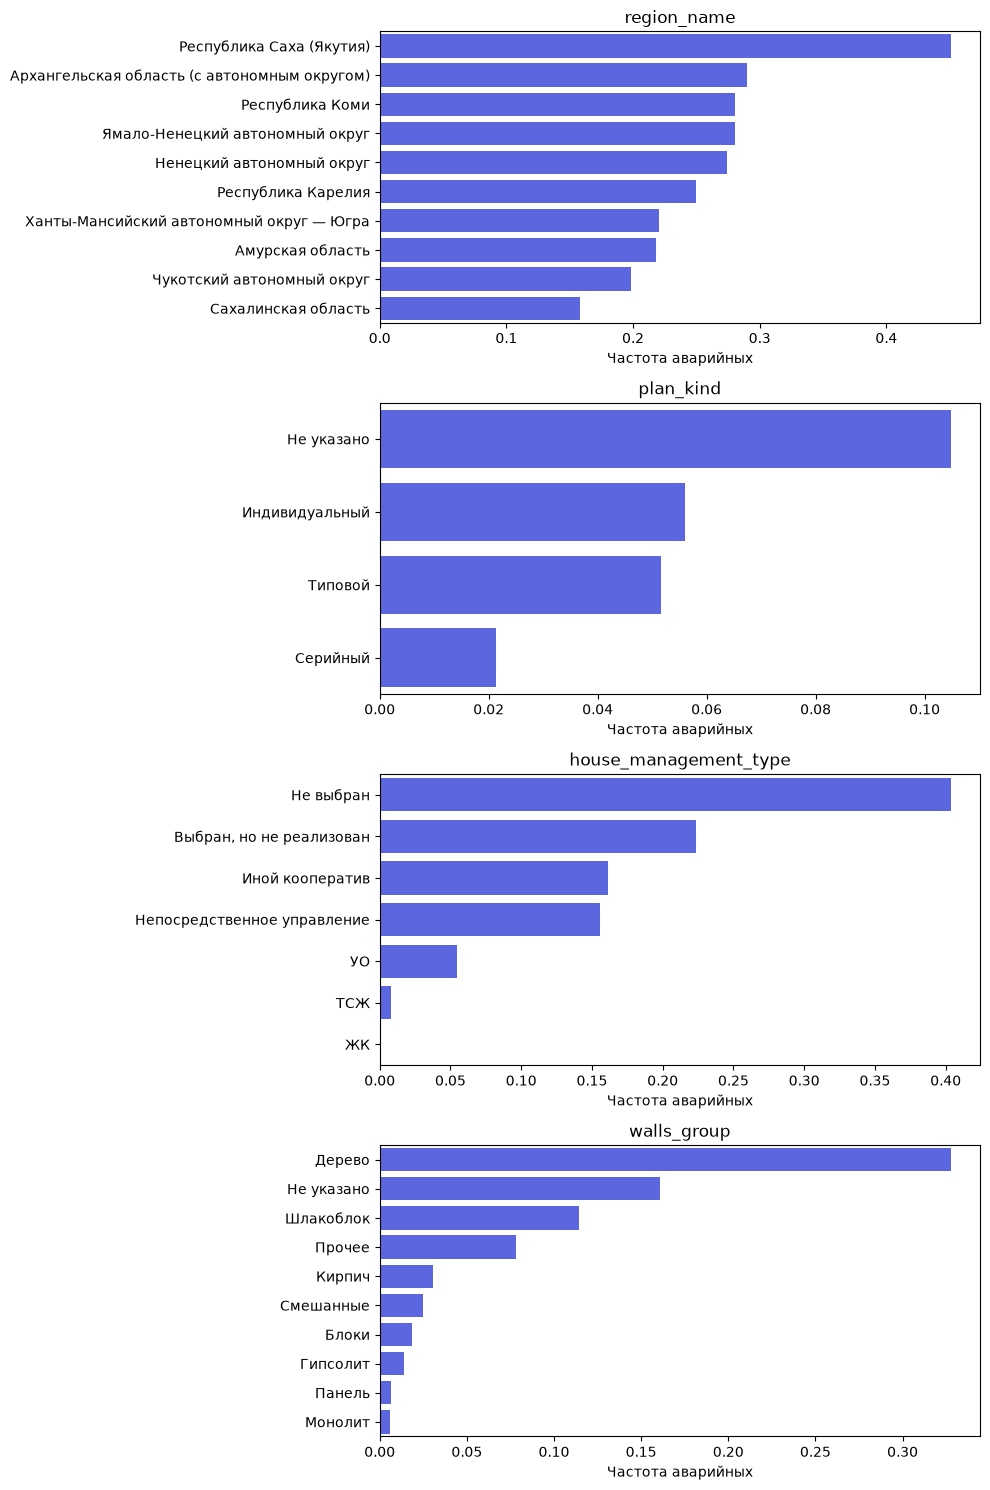

In [429]:
fig, axes = plt.subplots(4, 1, figsize=(10,15))
for ax, col in zip(axes.flat, set(category_features)-set(["municipality_oktmo"])):
    temp = df.groupby(col)[TARGET].mean().sort_values(ascending=False).head(10)
    sns.barplot(
        x=temp.values,
        y=temp.index,
        ax=ax,
        color=PLOT_COLOR
    )
    ax.set_ylabel("")
    ax.set_xlabel("Частота аварийных")
    ax.set_title(col, color=COLORS["text"])

plt.tight_layout()
plt.show()

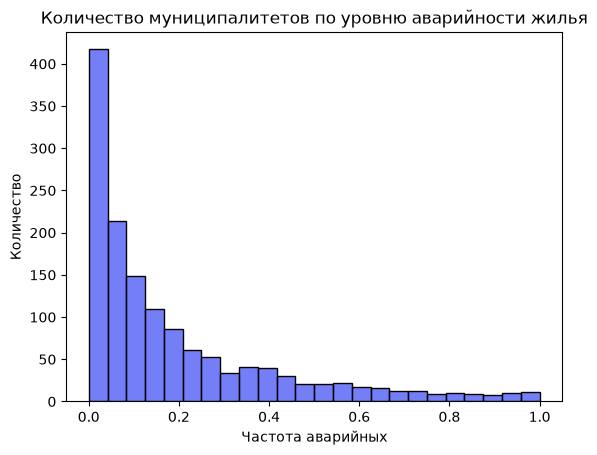

In [609]:
# Распределение муниципалитетов по аварийности

temp = df.groupby("municipality_oktmo")[TARGET].mean().reset_index().groupby(TARGET).count()
sns.histplot(
    x=temp.index,
    color=PLOT_COLOR
)
plt.title("Количество муниципалитетов по уровню аварийности жилья")
plt.xlabel("Частота аварийных")
plt.ylabel("Количество")
plt.show()

In [ ]:
df = df[(df['building_year'] > 1800) & (df['building_year'] <= 2025)]

df['is_reconstructed'] = df['reconstruction_year'].notna().astype(int)

df['is_dormitory'] = (df['regional_property'] == True) | (df['municipal_property'] == True)
df['is_dormitory'] = df['is_dormitory'].astype(int)

In [ ]:
cat_features =[
    'region_name', 'municipality_name', 'internal_walls_type',
    'house_manegement_type', 'plan_series', 'house_type'
]
df[cat_features] = df[cat_features].fillna('Не указано')

num_features =['building_year', 'total_area', 'residental_premises_area']
df[num_features] = df[num_features].fillna(df[num_features].median())

**График №1**: Дисбаланс целевой переменной
Этот график показывает, насколько мало в выборке аварийных домов по сравнению с нормальными.

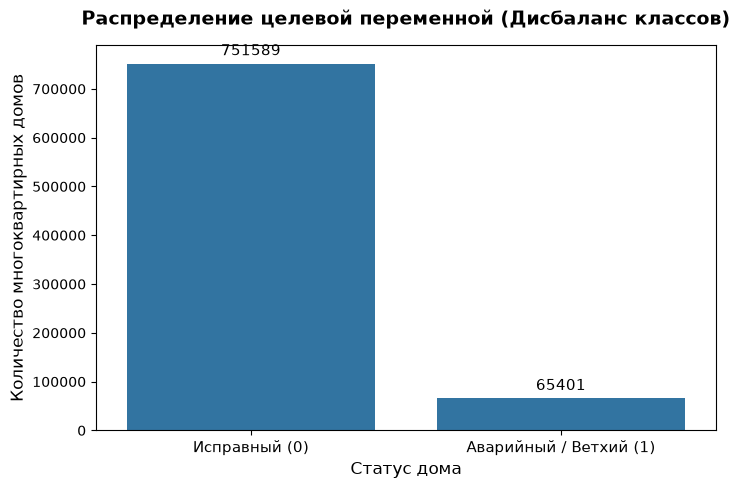

In [362]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))

ax = sns.countplot(data=df, x=TARGET)

plt.title('Распределение целевой переменной (Дисбаланс классов)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Статус дома', fontsize=12)
plt.ylabel('Количество многоквартирных домов', fontsize=12)

plt.xticks(ticks=[0, 1], labels=['Исправный (0)', 'Аварийный / Ветхий (1)'], fontsize=11)

for p in ax.patches:
    ax.annotate(format(p.get_height(), '.0f'),
                (p.get_x() + p.get_width() / 2., p.get_height()),
                ha = 'center', va = 'center',
                xytext = (0, 9),
                textcoords = 'offset points',
                fontsize=11)

plt.show()

Вывод по графику №1 (Дисбаланс классов):
Визуальный анализ распределения целевой переменной Target демонстрирует экстремальный дисбаланс (Class Imbalance). Объекты, официально признанные аварийными/ветхими, составляют абсолютное меньшинство генеральной совокупности. С точки зрения машинного обучения это означает риск того, что алгоритм будет склонен предсказывать мажоритарный класс (исправные дома). Для решения этой проблемы на этапе обучения модели потребуется применение механизма балансировки весов (class weights).

**График №2**: Возраст инфраструктуры

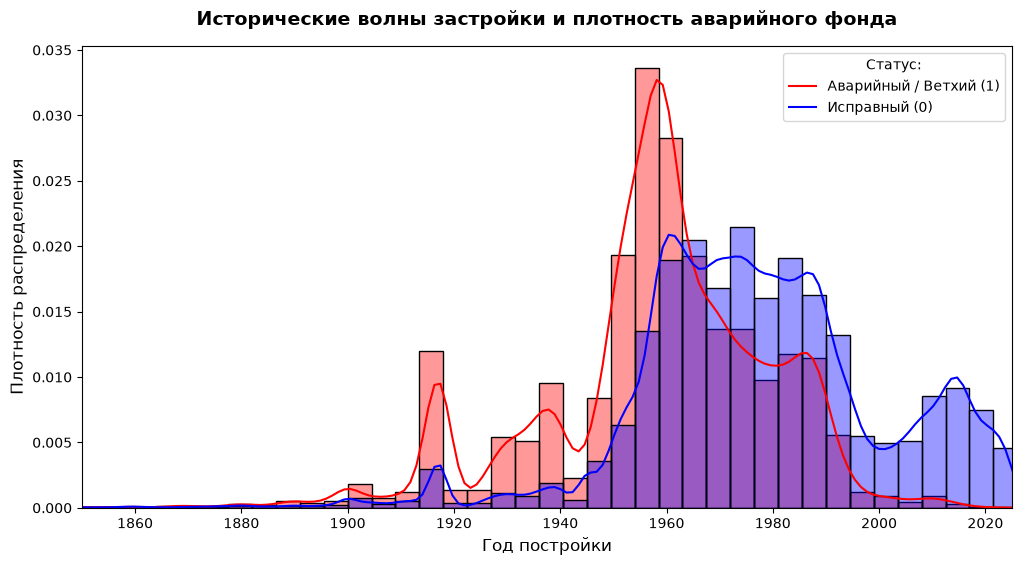

In [363]:
plt.figure(figsize=(12, 6))

sns.histplot(data=df, x='building_year', hue=TARGET,
             kde=True, bins=50, stat='density', common_norm=False,
             palette={0: 'blue', 1: 'red'}, alpha=0.4)

plt.title('Исторические волны застройки и плотность аварийного фонда', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Год постройки', fontsize=12)
plt.ylabel('Плотность распределения', fontsize=12)

plt.legend(title='Статус:', labels=['Аварийный / Ветхий (1)', 'Исправный (0)'])

plt.xlim(1850, 2025)

plt.show()

Вывод по графику №2 (Возраст инфраструктуры):
Гистограмма распределения жилищного фонда по годам постройки с разделением на классы аварийности подтверждает, что пик ветхого жилья смещен в сторону зданий, возведенных в первой половине XX века.

**График №3**: Институциональный срез



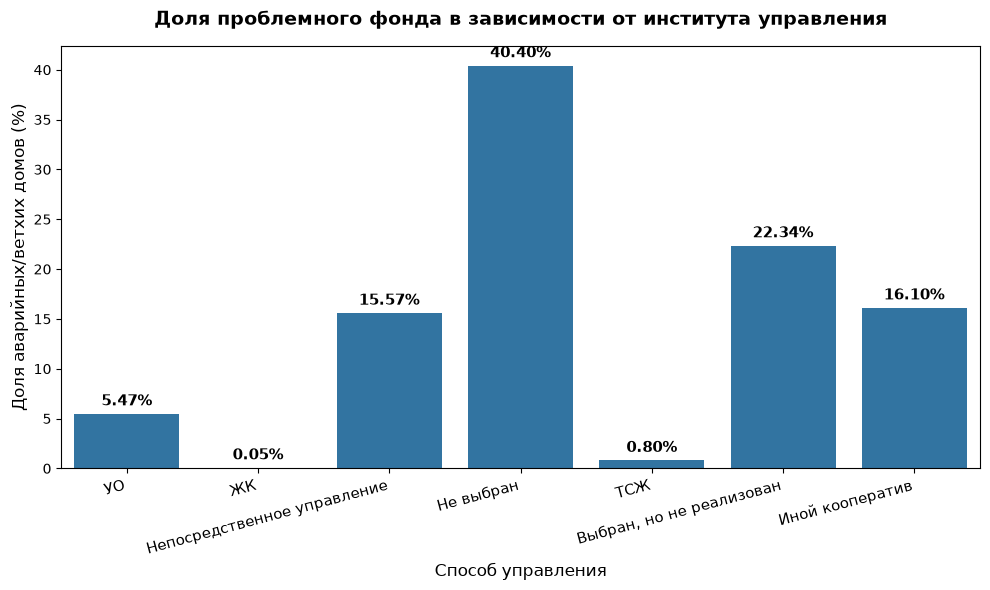

In [365]:
plt.figure(figsize=(10, 6))

df_plot = df.copy()
df_plot['Target_percent'] = df_plot[TARGET] * 100

ax = sns.barplot(data=df_plot, x='house_management_type', y='Target_percent',
                 errorbar=None)

plt.title('Доля проблемного фонда в зависимости от института управления', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Cпособ управления', fontsize=12)
plt.ylabel('Доля аварийных/ветхих домов (%)', fontsize=12)

plt.xticks(rotation=15, ha='right', fontsize=11)

for p in ax.patches:
    ax.annotate(f"{p.get_height():.2f}%",
                (p.get_x() + p.get_width() / 2., p.get_height()),
                ha = 'center', va = 'center',
                xytext = (0, 9),
                textcoords = 'offset points',
                fontsize=11, fontweight='bold')

plt.tight_layout()
plt.show()

Вывод по графику №3: Гистограмма иллюстрирует долю деградировавшего жилья в разрезе юридических форм управления. Отчетливо видна, что в сегменте домов, находящихся под управлением Товариществ собственников жилья (ТСЖ/ЖСК), доля аварийности крайне мала.

## Дизайн статистического исследования
В качестве базовой модели выбран алгоритм градиентного бустинга над деревьями решений — **CatBoost** (Categorical Boosting).

Его преимущества для данного исследования:
1. **Нативная обработка категорий**: CatBoost математически корректно работает со строковыми (текстовыми) признаками "под капотом", используя целевое кодирование (Target Encoding). Это позволяет модели находить сложные нелинейные связи между субъектом РФ, серией здания и его износом.
2. **Устойчивость к выбросам и неполным данным**: Древовидная архитектура бустинга робастна к нетипичным значениям (например, ошибкам ввода площади), которые неизбежно присутствуют в массивах государственной статистики.
3. **Встроенная компенсация дисбаланса**: Использование гиперпараметра auto_class_weights='Balanced' заставляет функцию потерь штрафовать модель пропорционально редкости аварийного класса, максимизируя способность алгоритма "отлавливать" проблемные объекты.

In [ ]:
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
from catboost import CatBoostClassifier, Pool

features = cat_features + num_features + ['is_reconstructed', 'is_dormitory']
X = df[features]
y = df['Target']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

model = CatBoostClassifier(
    iterations=500,
    cat_features=cat_features,
    auto_class_weights='Balanced', # Решает проблему редких аварийных домов
    random_seed=42,
    verbose=100
)

model.fit(X_train, y_train, eval_set=(X_test, y_test))

## Метрики оценки качества
Учитывая дисбаланс классов, стандартная метрика **Accuracy** (доля правильных ответов) является нерепрезентативной. Оценка качества алгоритма будет производиться на основе метрик **Precision** (точность), **Recall** (полнота), а также метрики **F1-score** и матрицы ошибок (**Confusion Matrix**). Для интерпретации социологических результатов будет применен анализ важности признаков (**Feature Importances**).

In [ ]:
preds = model.predict(X_test)
print(classification_report(y_test, preds))

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

feature_importances = model.get_feature_importance()
sns.barplot(x=feature_importances, y=X.columns)
plt.title("Важность признаков (Feature Importances)")
plt.show()

### Вывод по Feature Importances:
1. Физические признаки
- Абсолютным лидером по силе предсказания ожидаемо стал **building_year** (Год постройки). Это подтверждает адекватность модели: законы физики и естественный износ материалов выступают первичным фактором риска. В связке с ним работают структурные характеристики: **total_area** (Общая площадь) и **internal_walls_type** (Материал стен). Высокая значимость площади объясняется тем, что основу аварийного фонда исторически составляют малоэтажные дома небольшой площади (например, двухэтажные деревянные бараки), в то время как крупные массивы поздней советской застройки деградируют медленнее.
2. Социально-пространственное неравенство
- Наибольший интерес представляет то, что пространственно-географические признаки — **municipality_name** (Муниципалитет) и **region_name** (Регион) — заняли 2-е и 3-е места среди всех факторов (не считая площади), в совокупности формируя колоссальный вес в принятии решения моделью.
Это доказывает выдвинутую гипотезу: статус «аварийного дома» — это социально-бюрократический конструкт. При одинаковом возрасте, площади и материале стен вероятность признания дома аварийным кардинально различается в зависимости от субъекта РФ и конкретного города. Это прямое отражение бюджетной обеспеченности: богатые муниципалитеты имеют средства на расселение и быстрее "навешивают" статус аварийности на старый фонд, тогда как в депрессивных регионах процесс бюрократически тормозится.
3. Роль институтов управления
- Институциональный признак **house_manegement_type** (Способ управления) вошел в ядро значимых факторов. Хотя его глобальный вес уступает возрасту и географии, его влияние остается статистически существенным. Алгоритм учитывает юридическую форму управления (например, защитный эффект ТСЖ по сравнению с муниципальными УК) при оценке риска деградации, что подтверждает важность прав коллективной собственности.
4. Специфика бинарных признаков
- Сконструированные бинарные признаки **is_reconstructed** (Факт реконструкции) и **is_dormitory** (Статус общежития) показали низкую глобальную важность. С методологической точки зрения машинного обучения это легко объяснимо: доля общежитий и реконструированных домов в генеральной совокупности (950 тыс. зданий) ничтожно мала. Алгоритм редко использует эти признаки для разбиения всей выборки. Однако их низкая глобальная важность не отменяет их высокой локальной значимости: для конкретного здания сам факт наличия статуса "общежитие" может выступать критическим триггером разрушения, что требует дальнейшего изучения

## Вывод
Таким образом, первоначальная исследовательская гипотеза подтвердилась: статус аварийности дома не является случайной, а алгоритмически выводим из набора объективных характеристик здания и институциональной среды.